<a href="https://colab.research.google.com/github/PauloHenriqque/dashboard-xai-futebol/blob/main/notebooks/TCC_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Coleta e Definição do Escopo de Dados (API StatsBomb)
Para o desenvolvimento deste trabalho, optou-se pela utilização da base de dados aberta da StatsBomb. A fim de garantir que a Inteligência Artificial mapeasse exclusivamente os comportamentos espaciais e táticos do futebol moderno, o escopo da amostra foi delimitado a 6 competições de elite disputadas nos últimos 10 anos, englobando grandes seleções e o ápice do futebol de clubes.

In [ ]:
!pip install statsbombpy shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [statsbombpy]


In [ ]:
from statsbombpy import sb
import pandas as pd
import warnings

warnings.filterwarnings('ignore')

# 1. Puxa a tabela completa de competições
competicoes = sb.competitions()

# 2. Cria a coluna de ano
competicoes['ano_inicio'] = competicoes['season_name'].astype(str).str[:4].astype(int)

# 3. Filtra dinamicamente: A partir de 2016 E apenas Futebol Masculino
competicoes_masculinas = competicoes[
    (competicoes['ano_inicio'] >= 2016) &
    (competicoes['competition_gender'] == 'male')
]

print(f"🏆 MAPEANDO COMPETIÇÕES MASCULINAS A PARTIR DE 2016 (Total: {len(competicoes_masculinas)} torneios):")
ids_dos_jogos = []

for index, row in competicoes_masculinas.iterrows():
    comp_id = row['competition_id']
    season_id = row['season_id']
    nome_competicao = row['competition_name']
    nome_temporada = row['season_name']

    print(f" - {nome_competicao} ({nome_temporada})")

    # Extrai as partidas daquela edição
    partidas = sb.matches(competition_id=comp_id, season_id=season_id)
    ids_dos_jogos.extend(partidas['match_id'].tolist())

print("-" * 50)
print(f"Total de partidas definidas para o escopo: {len(ids_dos_jogos)} jogos")

🏆 MAPEANDO COMPETIÇÕES MASCULINAS A PARTIR DE 2016 (Total: 19 torneios):
 - 1. Bundesliga (2023/2024)
 - African Cup of Nations (2023)
 - Champions League (2018/2019)
 - Champions League (2017/2018)
 - Champions League (2016/2017)
 - Copa America (2024)
 - FIFA World Cup (2022)
 - FIFA World Cup (2018)
 - Indian Super league (2021/2022)
 - La Liga (2020/2021)
 - La Liga (2019/2020)
 - La Liga (2018/2019)
 - La Liga (2017/2018)
 - La Liga (2016/2017)
 - Ligue 1 (2022/2023)
 - Ligue 1 (2021/2022)
 - Major League Soccer (2023)
 - UEFA Euro (2024)
 - UEFA Euro (2020)
--------------------------------------------------
Total de partidas definidas para o escopo: 702 jogos


2. Mineração dos Dados (Data Mining)
O algoritmo abaixo percorre sequencialmente todas as partidas definidas no escopo, isolando exclusivamente os eventos táticos de interesse para os modelos preditivos: Passes e Finalizações. Uma rotina de tolerância a falhas (Retries) foi implementada para garantir a estabilidade do download frente às oscilações da API.

In [ ]:
import pandas as pd
import time
from tqdm import tqdm
from statsbombpy import sb

todos_os_passes = []
todas_as_finalizacoes = []

print(f"Iniciando a mineração de dados para {len(ids_dos_jogos)} partidas...")

for match_id in tqdm(ids_dos_jogos):
    sucesso = False
    tentativas = 0

    while not sucesso and tentativas < 5:
        try:
            eventos_do_jogo = sb.events(match_id=match_id)

            if 'Pass' in eventos_do_jogo['type'].values:
                passes = eventos_do_jogo[eventos_do_jogo['type'] == 'Pass']
                todos_os_passes.append(passes)

            if 'Shot' in eventos_do_jogo['type'].values:
                finalizacoes = eventos_do_jogo[eventos_do_jogo['type'] == 'Shot']
                todas_as_finalizacoes.append(finalizacoes)

            sucesso = True

        except Exception as e:
            tentativas += 1
            time.sleep(3)
            if tentativas == 5:
                print(f"\n⚠️ Falha definitiva na partida {match_id}.")

df_passes = pd.concat(todos_os_passes, ignore_index=True)
df_finalizacoes = pd.concat(todas_as_finalizacoes, ignore_index=True)

df_passes.to_csv('passes_copas_modernas.csv', index=False)
df_finalizacoes.to_csv('finalizacoes_copas_modernas.csv', index=False)

print("\n✅ Extração concluída e salva em CSV!")

Iniciando a mineração de dados para 702 partidas...


100%|██████████| 702/702 [07:40<00:00,  1.52it/s]



✅ Extração concluída e salva em CSV!


3. Engenharia de Recursos e Imputação de Valores Ausentes
Nesta etapa de Feature Engineering, as coordenadas cartesianas fornecidas pela API (com comprimento 120 e largura 80) são decompostas em eixos independentes. A variável preditora de pressão defensiva (under_pressure) tem seus dados ausentes convertidos para 0 (indicando ausência de pressão), enquanto as Features Alvo (is_successful e is_goal) são consolidadas em variáveis booleanas.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Extração das Coordenadas X e Y
df_finalizacoes[['X', 'Y']] = pd.DataFrame(df_finalizacoes['location'].tolist(), index=df_finalizacoes.index)
df_finalizacoes['distancia_gol'] = np.sqrt((120 - df_finalizacoes['X'])**2 + (40 - df_finalizacoes['Y'])**2)

# Imputação de Nulos: Pressão, Chute de Primeira e Tipo de Jogada
df_finalizacoes['under_pressure'] = df_finalizacoes['under_pressure'].fillna(False).astype(int)
df_finalizacoes['play_pattern'] = df_finalizacoes['play_pattern'].fillna('Regular Play')

if 'shot_first_time' in df_finalizacoes.columns:
    df_finalizacoes['shot_first_time'] = df_finalizacoes['shot_first_time'].fillna(False).astype(int)
else:
    df_finalizacoes['shot_first_time'] = 0

# Variável Alvo do xG
df_finalizacoes['is_goal'] = df_finalizacoes['shot_outcome'].apply(lambda x: 1 if x == 'Goal' else 0)

qtd_antes = len(df_passes)

# Dropando passes sem destino (nulos graves)
df_passes = df_passes.dropna(subset=['pass_end_location'])

qtd_depois = len(df_passes)
print(f"Foram removidos {qtd_antes - qtd_depois} registros nulos!")

# Extração de Coordenadas de Início e Fim
df_passes[['X_inicio', 'Y_inicio']] = pd.DataFrame(df_passes['location'].tolist(), index=df_passes.index)
df_passes[['X_fim', 'Y_fim']] = pd.DataFrame(df_passes['pass_end_location'].tolist(), index=df_passes.index)

# A Mágica Matemática: Distância e Ângulo
df_passes['pass_length'] = np.sqrt((df_passes['X_fim'] - df_passes['X_inicio'])**2 + (df_passes['Y_fim'] - df_passes['Y_inicio'])**2)
df_passes['pass_angle'] = np.arctan2(df_passes['Y_fim'] - df_passes['Y_inicio'], df_passes['X_fim'] - df_passes['X_inicio'])

# Imputação de Variáveis Categóricas e Booleanas
df_passes['under_pressure'] = df_passes['under_pressure'].fillna(False).astype(int)

# Tratamento do Cruzamento (Pode vir como 'pass_cross' ou 'cross' dependendo da API)
if 'pass_cross' in df_passes.columns:
    df_passes['pass_cross'] = df_passes['pass_cross'].fillna(False).astype(int)
elif 'cross' in df_passes.columns:
    df_passes['pass_cross'] = df_passes['cross'].fillna(False).astype(int)
else:
    df_passes['pass_cross'] = 0

# Tratamento da Altura do Passe (Ground, Low, High Pass)
if 'pass_height' in df_passes.columns:
    df_passes['pass_height'] = df_passes['pass_height'].fillna('Ground Pass')
else:
    df_passes['pass_height'] = 'Ground Pass'

# Variável Alvo dos Passes (O que causou o erro)
df_passes['is_successful'] = df_passes['pass_outcome'].isnull().astype(int)

print("✅ Engenharia de xG e Passes (Física Vetorial Aplicada) concluída com sucesso!")

Foram removidos 0 registros nulos!
✅ Engenharia de xG e Passes (Física Vetorial Aplicada) concluída com sucesso!


4. Auditoria de Volume e Desbalanceamento de Classes
A representatividade da base de dados e a distribuição entre sucessos e falhas determinam a escolha da métrica de avaliação. No contexto futebolístico, finalizações configuram-se como anomalias de baixo sucesso (desbalanceamento negativo), enquanto passes assumem uma classe majoritária de manutenção de posse (desbalanceamento positivo).

In [ ]:
print("--- AUDITORIA DA AMOSTRA: FINALIZAÇÕES (xG) ---")
contagem_xg = df_finalizacoes['is_goal'].value_counts()
print(f"Volume Total: {len(df_finalizacoes)} finalizações")
print(f"Classe 0 (Falha): {contagem_xg[0]} eventos | Classe 1 (Gol): {contagem_xg[1]} eventos")
print(f"Taxa de Sucesso Base: {df_finalizacoes['is_goal'].mean() * 100:.1f}%\n")

print("--- AUDITORIA DA AMOSTRA: PASSES ---")
contagem_passes = df_passes['is_successful'].value_counts()
print(f"Volume Total: {len(df_passes)} passes")
print(f"Classe 1 (Sucesso): {contagem_passes[1]} eventos | Classe 0 (Erro): {contagem_passes[0]} eventos")
print(f"Taxa de Sucesso Base: {df_passes['is_successful'].mean() * 100:.1f}%")

--- AUDITORIA DA AMOSTRA: FINALIZAÇÕES (xG) ---
Volume Total: 17968 finalizações
Classe 0 (Falha): 15819 eventos | Classe 1 (Gol): 2149 eventos
Taxa de Sucesso Base: 12.0%

--- AUDITORIA DA AMOSTRA: PASSES ---
Volume Total: 710561 passes
Classe 1 (Sucesso): 582525 eventos | Classe 0 (Erro): 128036 eventos
Taxa de Sucesso Base: 82.0%


5. Particionamento e Definição das Variáveis
Os conjuntos de dados foram submetidos à técnica Holdout (Split 80/20). Variáveis categóricas puras (como a parte do corpo utilizada no chute) passaram pelo processo de One-Hot Encoding (get_dummies) para adaptação à matriz matemática requerida pelos algoritmos.

In [ ]:
from sklearn.model_selection import train_test_split

# Seleção baseada no novo Dicionário Justificado
features_xg = ['distancia_gol', 'X', 'Y', 'under_pressure', 'shot_first_time', 'shot_body_part', 'shot_type', 'play_pattern']

# One-Hot Encoding para converter texto em matriz numérica
X_xg = pd.get_dummies(df_finalizacoes[features_xg], columns=['shot_body_part', 'shot_type', 'play_pattern'], drop_first=True)
X_xg = X_xg.astype(float) # Segurança para o XGBoost
y_xg = df_finalizacoes['is_goal']

X_train_xg, X_test_xg, y_train_xg, y_test_xg = train_test_split(
    X_xg, y_xg, test_size=0.2, random_state=42, stratify=y_xg
)

# Seleção baseada no novo Dicionário Justificado
features_passe = ['pass_length', 'pass_angle', 'X_inicio', 'Y_inicio', 'under_pressure', 'pass_cross', 'pass_height']

# One-Hot Encoding para a Altura do Passe
X_passe = pd.get_dummies(df_passes[features_passe], columns=['pass_height'], drop_first=True)
X_passe = X_passe.astype(float)
y_passe = df_passes['is_successful']

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_passe, y_passe, test_size=0.2, random_state=42, stratify=y_passe
)

print(f"🧠 Matriz X_train_xg: {X_train_xg.shape[1]} atributos preditivos")
print(f"🧠 Matriz X_train_p: {X_train_p.shape[1]} atributos preditivos")

print("\n🎯 DATAFRAME DE TREINAMENTO: FINALIZAÇÕES (xG)")
print("Variáveis preditoras consolidadas após Feature Engineering (One-Hot Encoding aplicado):")
display(X_xg.head())

print("\n👟 DATAFRAME DE TREINAMENTO: PASSES")
print("Variáveis preditoras consolidadas após Feature Engineering:")
display(X_passe.head())

🧠 Matriz X_train_xg: 19 atributos preditivos
🧠 Matriz X_train_p: 8 atributos preditivos

🎯 DATAFRAME DE TREINAMENTO: FINALIZAÇÕES (xG)
Variáveis preditoras consolidadas após Feature Engineering (One-Hot Encoding aplicado):


,distancia_gol,X,Y,under_pressure,shot_first_time,shot_body_part_Left Foot,shot_body_part_Other,shot_body_part_Right Foot,shot_type_Free Kick,shot_type_Open Play,shot_type_Penalty,play_pattern_From Counter,play_pattern_From Free Kick,play_pattern_From Goal Kick,play_pattern_From Keeper,play_pattern_From Kick Off,play_pattern_From Throw In,play_pattern_Other,play_pattern_Regular Play
0,18.669762,107.0,53.4,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,23.500213,96.5,39.9,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,32.272124,88.2,45.5,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,23.385679,98.5,49.2,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,9.070832,111.2,37.8,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0



👟 DATAFRAME DE TREINAMENTO: PASSES
Variáveis preditoras consolidadas após Feature Engineering:


,pass_length,pass_angle,X_inicio,Y_inicio,under_pressure,pass_cross,pass_height_High Pass,pass_height_Low Pass
0,2.773085,-2.694073,61.0,40.1,0.0,0.0,0.0,0.0
1,25.994230,2.648693,58.8,38.6,0.0,0.0,0.0,0.0
2,66.765860,-0.764215,37.9,52.2,0.0,0.0,1.0,0.0
3,14.431216,0.814801,84.3,6.2,0.0,0.0,0.0,1.0
4,10.200000,0.000000,25.9,63.4,0.0,0.0,0.0,1.0


5.5 - nova célula - balanceamento (undersampling, oversample, hybridsample)
pesos para o tipo de dado - ver se tem no xgboost

In [ ]:
import pandas as pd
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, brier_score_loss
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTEENN
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. FUNÇÃO DE AVALIAÇÃO (COM ARREDONDAMENTO)
# ==========================================
def avaliar_modelo_limiar(y_true, y_prob, nome_modelo, limiar=0.5):
    y_pred = (y_prob >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    especificidade = tn / (tn + fp) if (tn + fp) > 0 else 0
    return {
        'Modelo': nome_modelo,
        'Limiar': f"{limiar*100:.0f}%",
        'AUC-ROC': round(roc_auc_score(y_true, y_prob), 4),
        'Acurácia': round(accuracy_score(y_true, y_pred), 4),
        'Precisão': round(precision_score(y_true, y_pred, zero_division=0), 4),
        'Sensibilidade (Recall)': round(recall_score(y_true, y_pred, zero_division=0), 4),
        'Especificidade': round(especificidade, 4),
        'F1-Score': round(f1_score(y_true, y_pred, zero_division=0), 4),
        'Brier Score': round(brier_score_loss(y_true, y_prob), 4)
    }

# ==========================================
# 2. MOTOR DO SUPER BENCHMARK
# ==========================================
def gerar_super_benchmark(X_tr, y_tr, X_te, y_te, peso_alvo):
    # Modelos Base (Sem penalização)
    modelos_base = {
        "LR": LogisticRegression(max_iter=1000, random_state=42),
        "DT": DecisionTreeClassifier(max_depth=10, random_state=42),
        "RF": RandomForestClassifier(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42),
        "XGBoost": xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=42)
    }

    # Modelos com Penalização (class_weight='balanced' ou scale_pos_weight nativo)
    modelos_penalizados = {
        "LR": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
        "DT": DecisionTreeClassifier(max_depth=10, class_weight='balanced', random_state=42),
        "RF": RandomForestClassifier(n_estimators=100, max_depth=15, n_jobs=-1, class_weight='balanced', random_state=42),
        "XGBoost": xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', scale_pos_weight=peso_alvo, random_state=42)
    }

    print("  -> Gerando Oversampling (SMOTE)...")
    smote = SMOTE(random_state=42)
    X_sm, y_sm = smote.fit_resample(X_tr, y_tr)

    print("  -> Gerando Undersampling (RUS)...")
    rus = RandomUnderSampler(random_state=42)
    X_ru, y_ru = rus.fit_resample(X_tr, y_tr)

    print("  -> Gerando Hybrid (SMOTEENN) - Isso exige muito processamento matemático...")
    hybrid = SMOTEENN(random_state=42)
    X_hy, y_hy = hybrid.fit_resample(X_tr, y_tr)

    cenarios = [
        ("Sem Balanceamento", X_tr, y_tr, modelos_base),
        ("Oversampling", X_sm, y_sm, modelos_base),
        ("Undersampling", X_ru, y_ru, modelos_base),
        ("Hybridsampling", X_hy, y_hy, modelos_base),
        ("Penalização", X_tr, y_tr, modelos_penalizados)
    ]

    resultados = []
    for nome_cenario, X_cenario, y_cenario, dict_modelos in cenarios:
        # Linha de separação visual idêntica ao Excel
        resultados.append({
            'Modelo': f"--- {nome_cenario} ---", 'Limiar': '', 'AUC-ROC': '', 'Acurácia': '',
            'Precisão': '', 'Sensibilidade (Recall)': '', 'Especificidade': '', 'F1-Score': '', 'Brier Score': ''
        })
        print(f"  [Treinando IAs do Cenário: {nome_cenario}]")
        for nome_modelo, algoritmo in dict_modelos.items():
            algoritmo.fit(X_cenario, y_cenario)
            prob = algoritmo.predict_proba(X_te)[:, 1]
            res = avaliar_modelo_limiar(y_te, prob, nome_modelo, limiar=0.50)
            resultados.append(res)

    return pd.DataFrame(resultados)

# ==========================================
# 3. A GRANDE EXECUÇÃO: FINALIZAÇÕES (xG)
# ==========================================
print("🏆 INICIANDO A MATRIZ DE BENCHMARK PARA FINALIZAÇÕES (xG)")
peso_xg = len(y_train_xg[y_train_xg == 0]) / len(y_train_xg[y_train_xg == 1])
df_super_xg = gerar_super_benchmark(X_train_xg, y_train_xg, X_test_xg, y_test_xg, peso_xg)
display(df_super_xg)

# ==========================================
# 4. A GRANDE EXECUÇÃO: PASSES
# ==========================================
print("\n🏆 INICIANDO A MATRIZ DE BENCHMARK PARA PASSES")
print("⚠️ ATENÇÃO: Base de mais de meio milhão de passes.")
print("O SMOTEENN e o Random Forest farão cálculos pesados. Esta etapa pode demorar de 5 a 10 minutos. Pode ir beber água!")
peso_p = len(y_train_p[y_train_p == 0]) / len(y_train_p[y_train_p == 1])
df_super_p = gerar_super_benchmark(X_train_p, y_train_p, X_test_p, y_test_p, peso_p)
display(df_super_p)

# ==========================================
# 5. SALVANDO OS CAMPEÕES NA MEMÓRIA PARA A ETAPA DE SHAP E LIMIARES
# ==========================================
modelo_xgb_xg = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=42)
modelo_xgb_xg.fit(X_train_xg, y_train_xg)

modelo_xgb_passe = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=42)
modelo_xgb_passe.fit(X_train_p, y_train_p)

print("\n✅ Matriz de Benchmark concluída e modelos Campeões salvos na memória!")

🏆 INICIANDO A MATRIZ DE BENCHMARK PARA FINALIZAÇÕES (xG)
  -> Gerando Oversampling (SMOTE)...
  -> Gerando Undersampling (RUS)...
  -> Gerando Hybrid (SMOTEENN) - Isso exige muito processamento matemático...
  [Treinando IAs do Cenário: Sem Balanceamento]
  [Treinando IAs do Cenário: Oversampling]
  [Treinando IAs do Cenário: Undersampling]
  [Treinando IAs do Cenário: Hybridsampling]
  [Treinando IAs do Cenário: Penalização]


,Modelo,Limiar,AUC-ROC,Acurácia,Precisão,Sensibilidade (Recall),Especificidade,F1-Score,Brier Score
0,--- Sem Balanceamento ---,,,,,,,,
1,LR,50%,0.7695,0.8912,0.6757,0.1744,0.9886,0.2773,0.0879
2,DT,50%,0.6888,0.8837,0.5326,0.2279,0.9728,0.3192,0.1004
3,RF,50%,0.7481,0.889,0.6099,0.2,0.9826,0.3012,0.0914
4,XGBoost,50%,0.7492,0.8829,0.5266,0.207,0.9747,0.2972,0.0941
5,--- Oversampling ---,,,,,,,,
6,LR,50%,0.765,0.7251,0.25,0.6488,0.7355,0.3609,0.1855
7,DT,50%,0.7214,0.8189,0.3149,0.4372,0.8707,0.3661,0.1328
8,RF,50%,0.74,0.857,0.3966,0.3744,0.9226,0.3852,0.1112
9,XGBoost,50%,0.7438,0.8664,0.4224,0.3163,0.9412,0.3617,0.1042



🏆 INICIANDO A MATRIZ DE BENCHMARK PARA PASSES
⚠️ ATENÇÃO: Base de mais de meio milhão de passes.
O SMOTEENN e o Random Forest farão cálculos pesados. Esta etapa pode demorar de 5 a 10 minutos. Pode ir beber água!
  -> Gerando Oversampling (SMOTE)...
  -> Gerando Undersampling (RUS)...
  -> Gerando Hybrid (SMOTEENN) - Isso exige muito processamento matemático...
  [Treinando IAs do Cenário: Sem Balanceamento]
  [Treinando IAs do Cenário: Oversampling]
  [Treinando IAs do Cenário: Undersampling]
  [Treinando IAs do Cenário: Hybridsampling]
  [Treinando IAs do Cenário: Penalização]


,Modelo,Limiar,AUC-ROC,Acurácia,Precisão,Sensibilidade (Recall),Especificidade,F1-Score,Brier Score
0,--- Sem Balanceamento ---,,,,,,,,
1,LR,50%,0.8144,0.8347,0.8662,0.9442,0.3366,0.9035,0.113
2,DT,50%,0.8855,0.8695,0.9028,0.9423,0.5382,0.9221,0.093
3,RF,50%,0.9045,0.878,0.9114,0.9428,0.5829,0.9268,0.0868
4,XGBoost,50%,0.9089,0.8801,0.9148,0.9413,0.6013,0.9279,0.0852
5,--- Oversampling ---,,,,,,,,
6,LR,50%,0.8155,0.7934,0.9264,0.8124,0.7065,0.8657,0.1639
7,DT,50%,0.8835,0.8585,0.9248,0.9006,0.6669,0.9125,0.1091
8,RF,50%,0.9015,0.8659,0.9369,0.8968,0.7253,0.9164,0.0999
9,XGBoost,50%,0.9057,0.8661,0.9404,0.8934,0.7423,0.9163,0.0976



✅ Matriz de Benchmark concluída e modelos Campeões salvos na memória!


# 6

In [ ]:
import pandas as pd
import xgboost as xgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, brier_score_loss

# 1. Função de avaliação adaptada para aceitar Limiares Dinâmicos
def avaliar_modelo_limiar(y_true, y_prob, nome_modelo, limiar=0.5):
    """Calcula as métricas de classificação a partir de um limiar customizado"""
    y_pred = (y_prob >= limiar).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    especificidade = tn / (tn + fp) if (tn + fp) > 0 else 0

    return {
        'Modelo': nome_modelo,
        'Limiar': f"{limiar*100:.0f}%",
        'AUC-ROC': roc_auc_score(y_true, y_prob),
        'Acurácia': accuracy_score(y_true, y_pred),
        'Precisão': precision_score(y_true, y_pred, zero_division=0),
        'Sensibilidade (Recall)': recall_score(y_true, y_pred, zero_division=0),
        'Especificidade': especificidade,
        'F1-Score': f1_score(y_true, y_pred, zero_division=0),
        'Brier Score': brier_score_loss(y_true, y_prob)
    }

# 2. Treinando o modelo aqui mesmo para garantir que ele exista na memória
modelo_xgb_xg = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=42)
modelo_xgb_xg.fit(X_train_xg, y_train_xg)

# 3. Gerando as probabilidades
prob_xgb_xg = modelo_xgb_xg.predict_proba(X_test_xg)[:, 1]

# 4. Gerar a comparação usando as probabilidades do XGBoost Padrão
resultados_limiar = [
    avaliar_modelo_limiar(y_test_xg, prob_xgb_xg, "XGBoost Padrão", limiar=0.50),
    avaliar_modelo_limiar(y_test_xg, prob_xgb_xg, "XGBoost Padrão (Ajustado)", limiar=0.12)
]

print("🎯 IMPACTO DO AJUSTE DE LIMIAR NO MODELO XG")
display(pd.DataFrame(resultados_limiar).round(4))

🎯 IMPACTO DO AJUSTE DE LIMIAR NO MODELO XG


,Modelo,Limiar,AUC-ROC,Acurácia,Precisão,Sensibilidade (Recall),Especificidade,F1-Score,Brier Score
0,XGBoost Padrão,50%,0.7492,0.8829,0.5266,0.2070,0.9747,0.2972,0.0941
1,XGBoost Padrão (Ajustado),12%,0.7492,0.7348,0.2493,0.6047,0.7525,0.3530,0.0941


6.6

In [ ]:
import pandas as pd
import xgboost as xgb

# 1. Treinando o modelo de passes na hora para garantir que ele exista na memória
modelo_xgb_passe = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=42)
modelo_xgb_passe.fit(X_train_p, y_train_p)

# 2. Gerando as probabilidades a partir do modelo recém-treinado
prob_xgb_passe = modelo_xgb_passe.predict_proba(X_test_p)[:, 1]

# 3. Calculando o impacto do limiar (usando a função de avaliação já salva)
resultados_limiar_passe = [
    avaliar_modelo_limiar(y_test_p, prob_xgb_passe, "XGBoost Padrão", limiar=0.50),
    # Ajustando o limiar para a taxa de sucesso base (82%)
    avaliar_modelo_limiar(y_test_p, prob_xgb_passe, "XGBoost Padrão (Ajustado)", limiar=0.82)
]

print("🎯 IMPACTO DO AJUSTE DE LIMIAR NO MODELO DE PASSES")
display(pd.DataFrame(resultados_limiar_passe).round(4))

🎯 IMPACTO DO AJUSTE DE LIMIAR NO MODELO DE PASSES


,Modelo,Limiar,AUC-ROC,Acurácia,Precisão,Sensibilidade (Recall),Especificidade,F1-Score,Brier Score
0,XGBoost Padrão,50%,0.9089,0.8801,0.9148,0.9413,0.6013,0.9279,0.0852
1,XGBoost Padrão (Ajustado),82%,0.9089,0.8348,0.9599,0.8333,0.8417,0.8921,0.0852


7. Interpretabilidade do Modelo (XAI) com Valores SHAP
Uma vez validada a arquitetura XGBoost, aplicam-se os Shapley Additive Explanations para contornar o problema metodológico de "Caixa Preta". Esta etapa traduz as decisões probabilísticas da IA em insights de valor tático (Importância Global e Dependência Parcial).

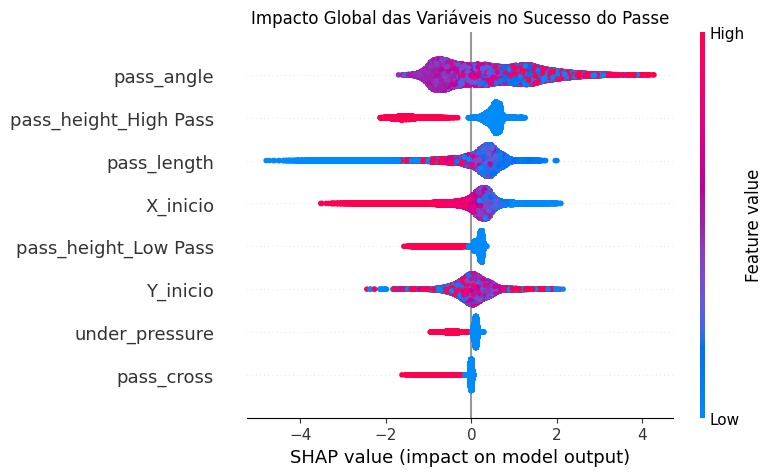

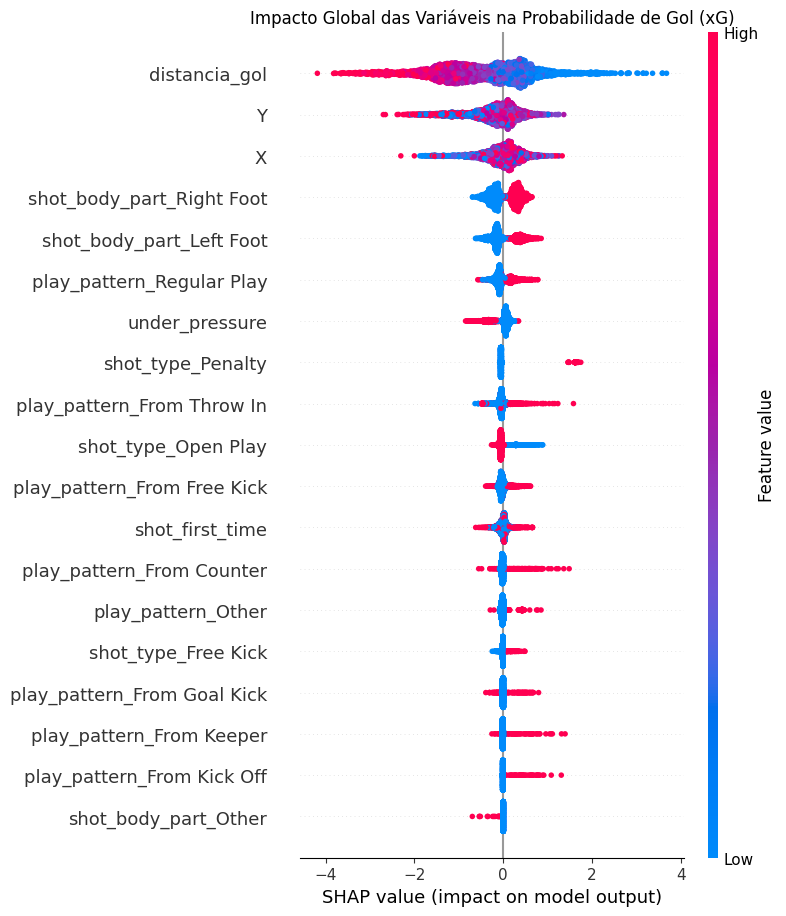

In [ ]:
import shap
import matplotlib.pyplot as plt

explainer_passe = shap.TreeExplainer(modelo_xgb_passe)
shap_values_passe = explainer_passe(X_test_p)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_passe, X_test_p, show=False)
plt.title("Impacto Global das Variáveis no Sucesso do Passe")
plt.show()

explainer_xg = shap.TreeExplainer(modelo_xgb_xg)
shap_values_xg = explainer_xg(X_test_xg)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_xg, X_test_xg, show=False)
plt.title("Impacto Global das Variáveis na Probabilidade de Gol (xG)")
plt.show()

8. Serialização para Deploy
O empacotamento final das estruturas de dados é realizado no padrão nativo .json. Este método previne overhead de carregamento e conflitos de memória C++ em ambientes de produção baseados na arquitetura Streamlit.

In [ ]:
modelo_xgb_xg.save_model('modelo_xg_copa.json')
modelo_xgb_passe.save_model('modelo_passe_copa.json')

print("✅ Modelos exportados com sucesso no formato JSON!")

✅ Modelos exportados com sucesso no formato JSON!


## Ajustar

1. Bater o martelo no criterio das escolhas das competições pra utilizar. (dúvida: champions league só tem as finais; copas do mundo completas apenas 2022 e 2018; a maioria das ligas tem poucas temporadas (1 ou 2); eles tem todos os jogos do messi pelo barcelona na la liga (mais ou menos 500 jogos, de 2004 a 2021), isso embasaria o modelo de alguma forma por só ter jogos do barcelona?)
2. Verificar os dados (quantidade) pós divisão de treino e teste (se preciso utilizar o stratify)
3. Definir mais métricas de avaliação: Acuracia, Precisão, Sensibilidade(recall), especificidade, f1-score. (AUC)
4. ver o dataframe dos dados para analisar os atributos disponiveis.
5. Definir todo o processo metodologico (Reunião Futura)